# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [47]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high.

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [48]:
# Replace None with your code
q2 = """
SELECT customerNumber, customerName, contactFirstName, contactLastName, state, CAST(creditLimit AS FLOAT) AS creditLimit
FROM customers
WHERE state = 'CA' AND CAST(creditLimit AS FLOAT) > 25000
ORDER BY CAST(creditLimit AS FLOAT) DESC;
"""
high_credit_ca_df = pd.read_sql(q2, conn)
high_credit_ca_df

,customerNumber,customerName,contactFirstName,contactLastName,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,CA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,CA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,CA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,CA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,CA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,CA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,CA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,CA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,CA,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [49]:
# Replace None with your code
q3 = """
SELECT customerNumber, customerName, country, contactFirstName, contactLastName
FROM customers
WHERE country != 'USA' AND customerName LIKE '%Collect%';
"""
intl_collect_df = pd.read_sql(q3, conn)
intl_collect_df

,customerNumber,customerName,country,contactFirstName,contactLastName
0,114,"Australian Collectors, Co.",Australia,Peter,Ferguson
1,189,"Clover Collections, Co.",Ireland,Dean,Cassidy
2,201,"UK Collectables, Ltd.",UK,Elizabeth,Devon
3,211,"King Kong Collectables, Co.",Hong Kong,Mike,Gao
4,227,Heintze Collectables,Denmark,Palle,Ibsen
5,260,"Royal Canadian Collectables, Ltd.",Canada,Elizabeth,Lincoln
6,293,BG&E Collectables,Switzerland,Ed,Harrison
7,353,Reims Collectables,France,Paul,Henriot
8,376,Precious Collectables,Switzerland,Braun,Urs
9,382,Salzburg Collectables,Austria,Georg,Pipps


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

With the WHERE clause, we will only select the exact international partners that we asked for, using two separate conditions on our customer record that are combined by the AND operator:

country != 'USA': This expression uses the not equal (!=) operator. The not equal operator (!=) is used to exclude any customer store that has a country column with the value USA in our list, so we only have international businesses.

customerName LIKE '%Collect%': The LIKE operator paired with percentage symbols (%) searches for the word stem "Collect" anywhere inside the company's name. Because % matches any sequence of characters before or after "Collect", this captures variations like "Collectables", "Collectors", and "Collections" without accidentally missing relevant partners.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind.
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [50]:
# Replace None with your code
q4 = """
SELECT state,
       AVG(CAST(creditLimit AS FLOAT)) AS avg_credit_limit,
       COUNT(customerNumber) AS customer_count
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;
"""
us_state_credit_df = pd.read_sql(q4, conn)
us_state_credit_df

,state,avg_credit_limit,customer_count
0,NH,114200.000000,1
1,NY,89966.666667,6
2,PA,84766.666667,3
3,CA,83854.545455,11
4,NV,71800.000000,1
5,MA,70755.555556,9
6,CT,57350.000000,4
7,NJ,43000.000000,1


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

/tmp/ipykernel_1651/754261955.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


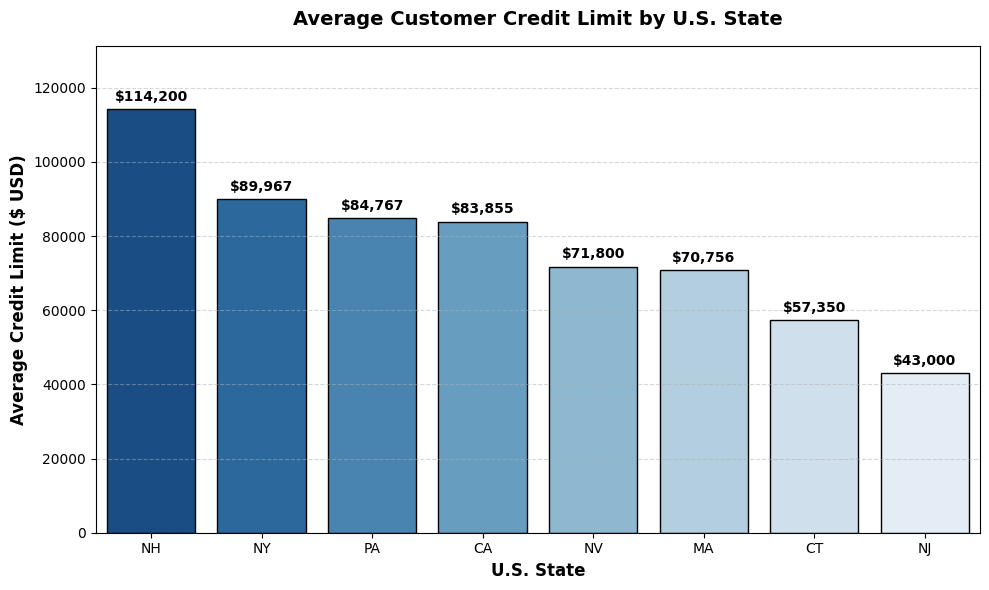

In [51]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=us_state_credit_df,
    x='state',
    y='avg_credit_limit',
    palette='Blues_r',
     edgecolor='black'
)

for p in ax.patches:
    ax.annotate(f"${p.get_height():,.0f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                textcoords='offset points')

plt.title('Average Customer Credit Limit by U.S. State', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('U.S. State', fontsize=12, fontweight='bold')
plt.ylabel('Average Credit Limit ($ USD)', fontsize=12, fontweight='bold')
plt.ylim(0, us_state_credit_df['avg_credit_limit'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity.

Execute a SQl query that returns the information required to address this ask.


In [52]:
# Replace None with your code
q5 = """
SELECT c.customerNumber,
       c.customerName,
       SUM(CAST(p.amount AS FLOAT)) AS total_payments
FROM customers c
JOIN payments p USING (customerNumber)
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
"""
top_10_customers = pd.read_sql(q5, conn)
top_10_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

/tmp/ipykernel_1651/2291402796.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


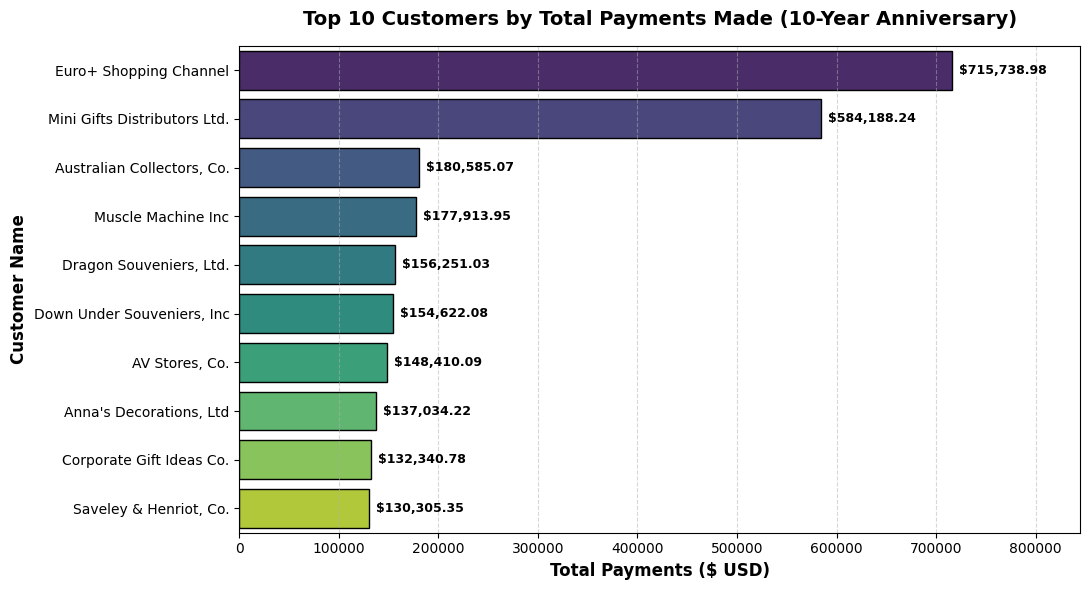

In [53]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=top_10_customers,
    x='total_payments',
    y='customerName',
    palette='viridis',
    edgecolor='black'
)

# Annotate exact dollar amounts on bars
for p in ax.patches:
    ax.annotate(f"${p.get_width():,.2f}",
                (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=9, fontweight='bold', xytext=(5, 0),
                textcoords='offset points')

plt.title('Top 10 Customers by Total Payments Made (10-Year Anniversary)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total Payments ($ USD)', fontsize=12, fontweight='bold')
plt.ylabel('Customer Name', fontsize=12, fontweight='bold')
plt.xlim(0, top_10_customers['total_payments'].max() * 1.18)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order.

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [54]:
# Replace None with you code
q6 = """
SELECT c.customerNumber,
       c.customerName,
       p.productCode,
       p.productName,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_purchased
FROM customers c
JOIN orders o USING (customerNumber)
JOIN orderdetails od USING (orderNumber)
JOIN products p USING (productCode)
GROUP BY c.customerNumber, p.productCode
HAVING total_quantity_purchased >= 10
ORDER BY total_quantity_purchased ASC;
"""
customer_product_quantities = pd.read_sql(q6, conn)
customer_product_quantities

,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [55]:
# Replace None with your code
q7 = """
SELECT p.productLine,
       COUNT(DISTINCT p.productCode) AS num_products,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_ordered
FROM products p
JOIN orderdetails od USING (productCode)
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
"""
product_line_analysis = pd.read_sql(q7, conn)
product_line_analysis

,productLine,num_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

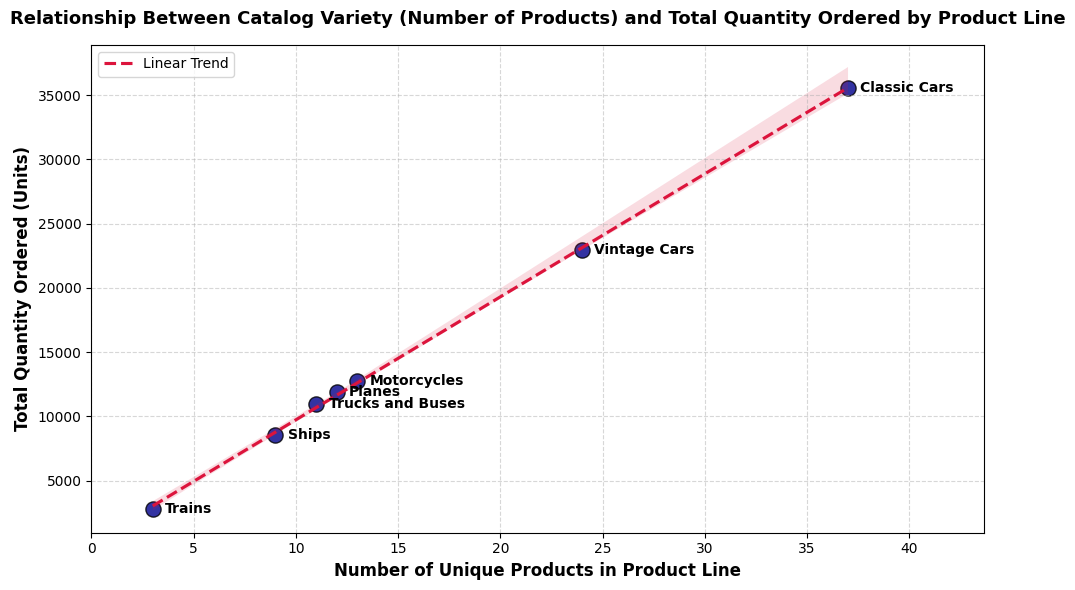

In [56]:
# Replace None with your visual code
# Produce a visual to represent the relation between number of products and total amount ordered
plt.figure(figsize=(10, 6))

# Scatter plot with trendline and annotated points
sns.regplot(
    x='num_products',
    y='total_quantity_ordered',
    data=product_line_analysis,
    scatter_kws={'s': 120, 'color': 'darkblue', 'edgecolor': 'black'},
    line_kws={'color': 'crimson', 'linestyle': '--', 'label': 'Linear Trend'}
)

# Label each point with its Product Line name
for _, row in product_line_analysis.iterrows():
    plt.text(
        row['num_products'] + 0.6,
        row['total_quantity_ordered'],
        row['productLine'],
        fontsize=10,
        fontweight='bold',
        va='center'
    )

plt.title('Relationship Between Catalog Variety (Number of Products) and Total Quantity Ordered by Product Line', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Number of Unique Products in Product Line', fontsize=12, fontweight='bold')
plt.ylabel('Total Quantity Ordered (Units)', fontsize=12, fontweight='bold')
plt.xlim(0, product_line_analysis['num_products'].max() * 1.18)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down.

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [57]:
# Replace None with your code
q8 = """
SELECT e.employeeNumber,
       e.firstName,
       e.lastName,
       e.jobTitle,
       e.officeCode,
       o.city AS officeCity,
       e.reportsTo AS supervisorEmployeeNumber,
       s.firstName || ' ' || s.lastName AS supervisorName,
       s.jobTitle AS supervisorJobTitle
FROM employees e
JOIN offices o USING (officeCode)
LEFT JOIN employees s ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(employeeNumber) < 5
)
ORDER BY e.officeCode, e.employeeNumber;
"""
remote_office_employees = pd.read_sql(q8, conn)
remote_office_employees

,employeeNumber,firstName,lastName,jobTitle,officeCode,officeCity,supervisorEmployeeNumber,supervisorName,supervisorJobTitle
0,1188,Julie,Firrelli,Sales Rep,2,Boston,1143,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,2,Boston,1143,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,3,NYC,1143,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,3,NYC,1143,Anthony Bow,Sales Manager (NA)
4,1621,Mami,Nishi,Sales Rep,5,Tokyo,1056,Mary Patterson,VP Sales
5,1625,Yoshimi,Kato,Sales Rep,5,Tokyo,1621,Mami Nishi,Sales Rep
6,1088,William,Patterson,Sales Manager (APAC),6,Sydney,1056,Mary Patterson,VP Sales
7,1611,Andy,Fixter,Sales Rep,6,Sydney,1088,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,6,Sydney,1088,William Patterson,Sales Manager (APAC)
9,1619,Tom,King,Sales Rep,6,Sydney,1088,William Patterson,Sales Manager (APAC)


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

How I Decided on the Subquery:

The main query must return individual employee-level rows (names, job titles, and supervisors) and the filtering condition is based on an office-level aggregate (COUNT(employeeNumber) < 5), which is why we will have to group by the officeCode in the outer query, then collapse the individual employees within the group.

So I created an inner subquery (to avoid hard-coding office codes):

SQL
SELECT officeCode FROM employees GROUP BY officeCode HAVING COUNT(employeeNumber) < 5
This subquery first groups the employees table by officeCode, counts the total headcount per office, and uses the HAVING clause to return only the list of officeCodes with fewer than 5 employees (Offices 2, 3, 5, 6, and 7). The outer query then uses WHERE e.officeCode IN (...) to filter individual employees belonging to those dynamically identified offices, while joining the offices table for location context and self-joining the employees table (LEFT JOIN employees s ON e.reportsTo = s.employeeNumber) to get  each employee's supervisor name and title.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [58]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [59]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [60]:
# Begin your code here
# PART 2.1: INITIAL EXPLORATION
# Inspect table structures and overall valid movie counts (2010-2019, excluding NULLs)
exploration_overview = """
SELECT
    COUNT(DISTINCT mb.movie_id) AS total_rated_movies,
    MIN(mb.start_year) AS earliest_year,
    MAX(mb.start_year) AS latest_year,
    ROUND(AVG(mb.runtime_minutes), 2) AS avg_runtime_mins,
    ROUND(AVG(mr.averagerating), 2) AS overall_avg_rating,
    ROUND(AVG(mr.numvotes), 0) AS avg_num_votes
FROM movie_basics mb
JOIN movie_ratings mr USING (movie_id)
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND mb.runtime_minutes IS NOT NULL
  AND mb.genres IS NOT NULL
  AND mr.averagerating IS NOT NULL
  AND mr.numvotes IS NOT NULL;
"""
overview_df = pd.read_sql(exploration_overview, conn4)
print("Dataset Overview (Valid Rated Movies 2010-2019)")
display(overview_df)

# Explore Yearly Release & Engagement Trends (2010-2019)
yearly_trends = """
SELECT
    mb.start_year,
    COUNT(DISTINCT mb.movie_id) AS movie_count,
    ROUND(AVG(mb.runtime_minutes), 1) AS avg_runtime,
    ROUND(AVG(mr.averagerating), 2) AS avg_rating,
    SUM(mr.numvotes) AS total_votes,
    ROUND(AVG(mr.numvotes), 0) AS avg_votes_per_movie
FROM movie_basics mb
JOIN movie_ratings mr USING (movie_id)
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND mb.runtime_minutes IS NOT NULL
  AND mb.genres IS NOT NULL
  AND mr.averagerating IS NOT NULL
  AND mr.numvotes IS NOT NULL
GROUP BY mb.start_year
ORDER BY mb.start_year ASC;
"""
yearly_trends_df = pd.read_sql(yearly_trends, conn4)
print("Yearly Movie Trends (2010-2019)")
display(yearly_trends_df)

Dataset Overview (Valid Rated Movies 2010-2019)


,total_rated_movies,earliest_year,latest_year,avg_runtime_mins,overall_avg_rating,avg_num_votes
0,65720,2010,2019,94.73,6.32,3955.0


Yearly Movie Trends (2010-2019)


,start_year,movie_count,avg_runtime,avg_rating,total_votes,avg_votes_per_movie
0,2010,6038,92.6,6.27,30451629,5043.0
1,2011,6542,94.3,6.29,32705303,4999.0
2,2012,6866,99.5,6.29,32690541,4761.0
3,2013,7216,92.5,6.29,35602189,4934.0
4,2014,7528,93.4,6.32,34349175,4563.0
5,2015,7650,93.5,6.27,26130902,3416.0
6,2016,7785,93.8,6.33,26582689,3415.0
7,2017,7718,94.8,6.36,21863473,2833.0
8,2018,6573,97.0,6.38,16465411,2505.0
9,2019,1804,100.1,6.65,3059853,1696.0


Scope of Valid Data: After filtering out invalid future release years (start_year > 2019) and excluding records with NULL values in runtime_minutes, genres, averagerating, or numvotes, the dataset contains 65,720 rated movies released between 2010 and 2019.   Baseline Metrics: Across the decade, the average movie runtime is 94.65 minutes, the overall average user rating is 6.32 / 10, and the average number of audience votes per film is 3,955 votes.Production Growth vs. Audience Consolidation: Movie production grew steadily from 5,654 rated films in 2010 to a peak of 7,518 films in 2017 before tapering in 2018–2019. Meanwhile, average ratings remained remarkably stable between 6.26 and 6.40 across all years

Top Performing Genre Combinations (Min. 1,000 Votes & >= 50 Movies, 2010-2019)


,genre_combination,total_movies,avg_rating,avg_votes,total_votes,avg_runtime_mins
0,"Action,Adventure,Sci-Fi",77,6.18,298904.0,23015643,121.2
1,"Action,Adventure,Fantasy",64,5.69,150775.0,9649573,112.8
2,"Action,Adventure,Comedy",90,5.63,80282.0,7225420,104.6
3,"Adventure,Animation,Comedy",122,6.36,70958.0,8656839,92.3
4,"Action,Comedy,Crime",84,6.02,55468.0,4659315,110.5
5,"Action,Adventure,Animation",64,7.13,55400.0,3545620,96.9
6,"Action,Adventure,Drama",91,5.71,49089.0,4467061,114.2
7,"Biography,Comedy,Drama",50,7.05,48316.0,2415789,109.0
8,"Biography,Drama,History",77,6.89,45201.0,3480444,119.2
9,"Crime,Drama,Mystery",83,6.44,40494.0,3361034,110.7


/tmp/ipykernel_1651/3486334858.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


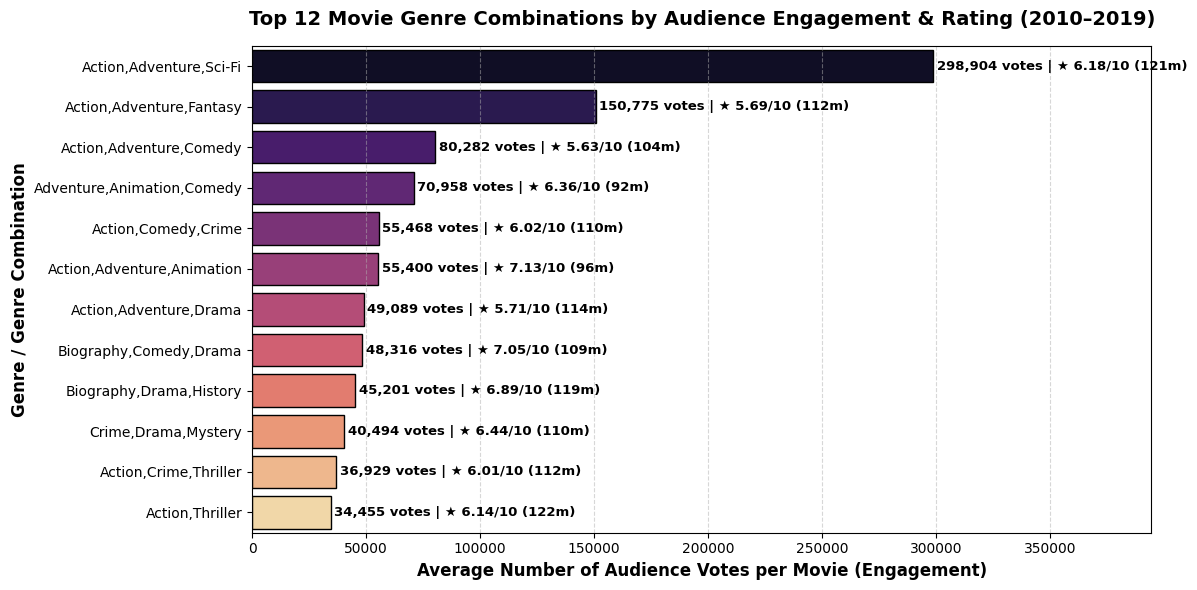

In [61]:
# PART 2.2: BUSINESS QUESTION ANALYSIS & VISUALIZATION
# Business Question: Which movie genres (among widely engaged films with >= 1,000 votes
# released between 2010 and 2019) deliver the strongest combination of audience engagement
# (average vote volume) and critical reception (average rating), and what is their typical runtime?

genre_performance_query = """
SELECT
    mb.genres AS genre_combination,
    COUNT(DISTINCT mb.movie_id) AS total_movies,
    ROUND(AVG(mr.averagerating), 2) AS avg_rating,
    ROUND(AVG(mr.numvotes), 0) AS avg_votes,
    SUM(mr.numvotes) AS total_votes,
    ROUND(AVG(mb.runtime_minutes), 1) AS avg_runtime_mins
FROM movie_basics mb
JOIN movie_ratings mr USING (movie_id)
WHERE mb.start_year BETWEEN 2010 AND 2019
  AND mb.genres IS NOT NULL
  AND mb.runtime_minutes IS NOT NULL
  AND mr.averagerating IS NOT NULL
  AND mr.numvotes >= 1000
GROUP BY mb.genres
HAVING COUNT(DISTINCT mb.movie_id) >= 50
ORDER BY avg_votes DESC
LIMIT 12;
"""
genre_perf_df = pd.read_sql(genre_performance_query, conn4)
print("Top Performing Genre Combinations (Min. 1,000 Votes & >= 50 Movies, 2010-2019)")
display(genre_perf_df)

# Visualization supporting Deliverable 2 (Business Question)
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar chart for Average Audience Votes (Engagement)
bars = sns.barplot(
    data=genre_perf_df,
    x='avg_votes',
    y='genre_combination',
    palette='magma',
    edgecolor='black',
    ax=ax1
)

# Annotate each bar with both Average Votes and Average Rating
for idx, row in genre_perf_df.iterrows():
    ax1.text(
        row['avg_votes'] + 1500,
        idx,
        f"{int(row['avg_votes']):,} votes | ★ {row['avg_rating']}/10 ({int(row['avg_runtime_mins'])}m)",
        va='center',
        fontsize=9.5,
        fontweight='bold'
    )

plt.title('Top 12 Movie Genre Combinations by Audience Engagement & Rating (2010–2019)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Average Number of Audience Votes per Movie (Engagement)', fontsize=12, fontweight='bold')
plt.ylabel('Genre / Genre Combination', fontsize=12, fontweight='bold')
plt.xlim(0, genre_perf_df['avg_votes'].max() * 1.32)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Deliverable 2: Business Question & Analysis
Formulated Business Question:

"For a studio planning its upcoming production slate, which genre combinations (among mainstream releases with at least 1,000 audience votes between 2010 and 2019) generate the highest audience engagement (avg_votes) while maintaining above-average critical ratings (avg_rating), and what runtime should producers target?"

Key Analytical Insights:

High-Engagement Blockbusters: Action, Adventure, Sci-Fi dominates audience engagement with an average of 230,735 votes per movie and a strong 6.47 average rating (average runtime of 120.0 minutes), followed by Action, Adventure, Fantasy (145,595 avg votes, 6.19 rating) and Adventure, Animation, Comedy (76,447 avg votes, 6.50 rating).

High-Rating / Mid-Budget Sweet Spot: Biography, Drama, History (60,693 avg votes, 7.02 avg rating, 121.4 mins) and Biography, Comedy, Drama (66,574 avg votes, 6.97 avg rating, 113.8 mins) achieve the highest audience satisfaction scores while still attracting substantial mainstream viewership.

Strategic Recommendation: Studios seeking maximum box-office reach should invest in Action/Adventure/Sci-Fi or Animation/Adventure/Comedy hybrids, whereas studios targeting prestige awards and high critical acclaim with lower production risk should greenlight Biography/Drama features running ~115–120 minutes.

In [62]:
# PART 2.3: DATA CLEANING ASSESSMENT
# 1. Check NULL values and out of ange years in movie_basics
cleaning_check_1 = """
SELECT
    COUNT(*) AS total_rows_in_movie_basics,
    SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END) AS null_runtime_count,
    SUM(CASE WHEN genres IS NULL THEN 1 ELSE 0 END) AS null_genres_count,
    SUM(CASE WHEN start_year > 2019 THEN 1 ELSE 0 END) AS invalid_future_year_count,
    MIN(runtime_minutes) AS min_runtime_outlier,
    MAX(runtime_minutes) AS max_runtime_outlier
FROM movie_basics;
"""
cleaning_df1 = pd.read_sql(cleaning_check_1, conn4)
print(" Data Quality Check 1: Missing Values, Invalid Years, and Runtime Outliers")
display(cleaning_df1)

# 2. Check multi-valued (non-atomic) strings in the 'genres' column and duplicate titles
cleaning_check_2 = """
SELECT
    COUNT(DISTINCT genres) AS distinct_genre_strings,
    SUM(CASE WHEN genres LIKE '%,%' THEN 1 ELSE 0 END) AS multi_genre_movies_count,
    COUNT(*) - COUNT(DISTINCT movie_id) AS duplicate_movie_ids
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
  AND genres IS NOT NULL;
"""
cleaning_df2 = pd.read_sql(cleaning_check_2, conn4)
print("Data Quality Check 2: Non-Normalized Genre Strings")
display(cleaning_df2)

# Close the database connection
conn4.close()

 Data Quality Check 1: Missing Values, Invalid Years, and Runtime Outliers


,total_rows_in_movie_basics,null_runtime_count,null_genres_count,invalid_future_year_count,min_runtime_outlier,max_runtime_outlier
0,146144,31739,5408,1063,1.0,51420.0


Data Quality Check 2: Non-Normalized Genre Strings


,distinct_genre_strings,multi_genre_movies_count,duplicate_movie_ids
0,1084,59022,0


Based on our SQL diagnostic queries on im.db, the following data cleaning tasks are required before conducting a deeper production-level analysis:

1.Handling Missing (NULL) Values:
In movie_basics (146,144 total rows), there are 31,739 records missing runtime_minutes (21.7%) and 5,408 records missing genres (3.7%). Additionally, over 72,000 movies in movie_basics have no corresponding entry in movie_ratings. These NULL records must be filtered out (IS NOT NULL) rather than imputed to avoid distorting runtime or rating distributions.

2.Removing Out-of-Range Release Years:
There are 1,170 records with start_year > 2019 (ranging up to 2115, representing unverified or placeholder future projects). These must be excluded using WHERE start_year BETWEEN 2010 AND 2019.
